In [29]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
folder = r'C:\Users\FeiyuanYang\OneDrive - Cambridge GaN Devices Ltd\Documents\CGD documents\Projects\P42016'
file1 = 'P42016 KR16.csv'
file2 = 'P42016 GD33.csv'
df1 = pd.read_csv(os.path.join(folder, file1), comment='#')  # Read the first CSV file, ignoring lines starting with '#'
df2 = pd.read_csv(os.path.join(folder, file2), comment='#')  # Read the second CSV file, ignoring lines starting with '#'

In [31]:
df2 = df2[:129]
df1['design'] = 'KR16'
df2['design'] = 'GD33'
for idx, row in df1.iterrows():
    parts = str(row["file"]).split(" ")
    df1.loc[idx, "Vds (V)"] = int(eval(parts[0][:-1]))
    df1.loc[idx, "Ids (A)"] = int(parts[1][:-1])
    df1.loc[idx, "Rg"] = eval(parts[2][:-1])
    df1.loc[idx, "Vg (V)"] = int(eval(parts[3][:-5]))

for idx, row in df2.iterrows():
    parts = str(row["file"]).split(" ")
    if str(row["file"]) == '400V 70A 15V 10rg.tss':
        df2.loc[idx, "Vds (V)"] = 400
        df2.loc[idx, "Ids (A)"] = 70
        df2.loc[idx, "Rg"] = 10.0
        df2.loc[idx, "Vg (V)"] = 15
        continue

    df2.loc[idx, "Vds (V)"] = int(eval(parts[0][:-1]))
    df2.loc[idx, "Ids (A)"] = int(parts[1][:-1])
    df2.loc[idx, "Rg"] = eval(parts[2][:-2])
    df2.loc[idx, "Vg (V)"] = int(eval(parts[3].split('vg')[0]))

df = pd.concat([df1, df2], ignore_index=True)

In [33]:
print(df['Rg'].unique())

[  0.   10.    2.2  22.    4.7  47.    1.  100. ]


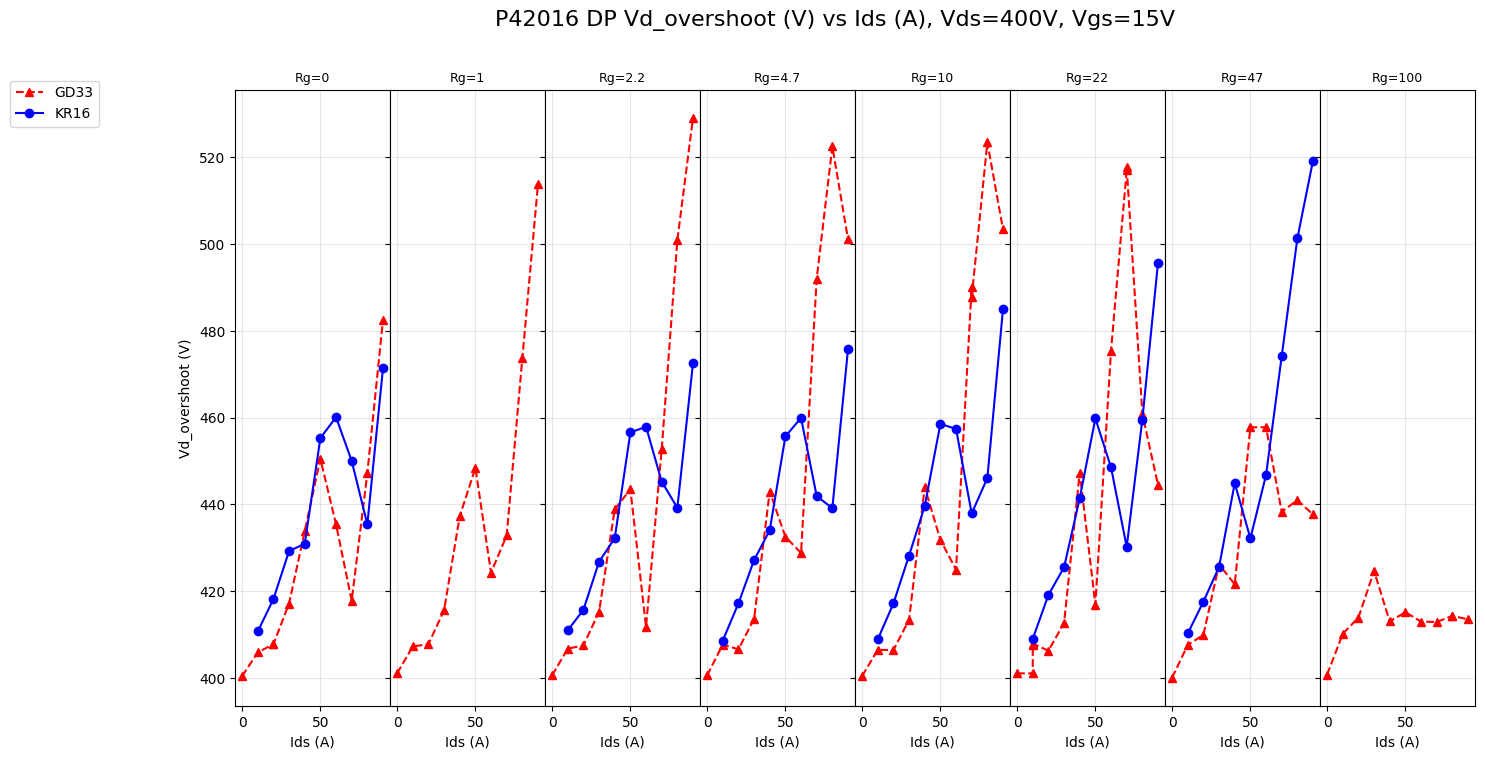

In [40]:
params = ['Vd_overshoot (V)']
vds = 400
vgs = 15
for param in params:
    df_plot = df[(df['Vg (V)'] == vgs) & (df['Vds (V)'] == vds)]
    conditions = [[0], [1], [2.2], [4.7], [10], [22], [47], [100]]

    fig, axes = plt.subplots(
        1,
        len(conditions),
        figsize=(2 * len(conditions), 8),
        sharex=True,
        sharey=True  # same y-axis for all designs
    )
    for ax, c in zip(axes, conditions):
        design_df = df_plot[(df_plot['Rg'] == c[0])]
        for conds, chip_df in design_df.groupby(['design']):
            chip_df = chip_df.sort_values('Ids (A)')
            if conds[0] == 'KR16':
                ax.plot(
                    chip_df['Ids (A)'],
                    chip_df[param],
                    marker='o',
                    linewidth=1.5,
                    color='blue',
                    label=str(f'{conds[0]}')
                )
            elif conds[0] == 'GD33':
                ax.plot(
                    chip_df['Ids (A)'],
                    chip_df[param],
                    marker='^',
                    linewidth=1.5,
                    linestyle='--',
                    color='red',
                    label=str(f'{conds[0]}')
                )

        ax.set_title(f'Rg={c[0]}', fontsize=9)
        ax.set_xlabel('Ids (A)')
        #ax.set_xlim([0, 170])
        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel(param)

    # Create a single legend from all chip_ids
    handles = []
    labels = []

    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for hh, ll in zip(h, l):
            if ll not in labels:
                handles.append(hh)
                labels.append(ll)

    fig.legend(
        handles,
        labels,
        loc='upper left',
        bbox_to_anchor=(-0.02, 0.9),
        #title='chip_id'
    )

    fig.suptitle(f'P42016 DP {param} vs Ids (A), Vds={vds}V, Vgs={vgs}V', fontsize=16)
    fig.subplots_adjust(wspace=0)
    plt.show()